In [1]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
from pathlib import Path

candidates = [Path('Sample - Superstore.csv'), Path('data/Sample - Superstore.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Put 'Sample - Superstore.csv' next to this notebook (or in a 'data/' folder).")

df = pd.read_csv(data_path, encoding='cp1252')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


# Buisness Analysis

In [3]:
print(df.shape)
df.info()

(9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity

In [4]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')

In [5]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicates    :', df.duplicated().sum())

Missing values: 0
Duplicates    : 0


In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Row ID,9994.0,4997.5,1.0,2499.25,4997.5,7495.75,9994.0,2885.163629
Order Date,9994,2016-04-30 00:07:12.259355,2014-01-03 00:00:00,2015-05-23 00:00:00,2016-06-26 00:00:00,2017-05-14 00:00:00,2017-12-30 00:00:00,NaN
Ship Date,9994,2016-05-03 23:06:58.571142,2014-01-07 00:00:00,2015-05-27 00:00:00,2016-06-29 00:00:00,2017-05-18 00:00:00,2018-01-05 00:00:00,NaN
Postal Code,9994.0,55190.379428,1040.0,23223.0,56430.5,90008.0,99301.0,32063.69335
Sales,9994.0,229.858001,0.444,17.28,54.49,209.94,22638.48,623.245101
Quantity,9994.0,3.789574,1.0,2.0,3.0,5.0,14.0,2.22511
Discount,9994.0,0.156203,0.0,0.0,0.2,0.2,0.8,0.206452
Profit,9994.0,28.656896,-6599.978,1.72875,8.6665,29.364,8399.976,234.260108


In [7]:
df['Profit'].describe()

count    9994.000000
mean       28.656896
std       234.260108
min     -6599.978000
25%         1.728750
50%         8.666500
75%        29.364000
max      8399.976000
Name: Profit, dtype: float64

In [8]:
print(f"Loss-making rows: {(df['Profit'] < 0).mean():.1%}")
print('Skew:', df[['Sales', 'Quantity', 'Discount', 'Profit']].skew().round(2).to_dict())

Loss-making rows: 18.7%
Skew: {'Sales': 12.97, 'Quantity': 1.28, 'Discount': 1.68, 'Profit': 7.56}


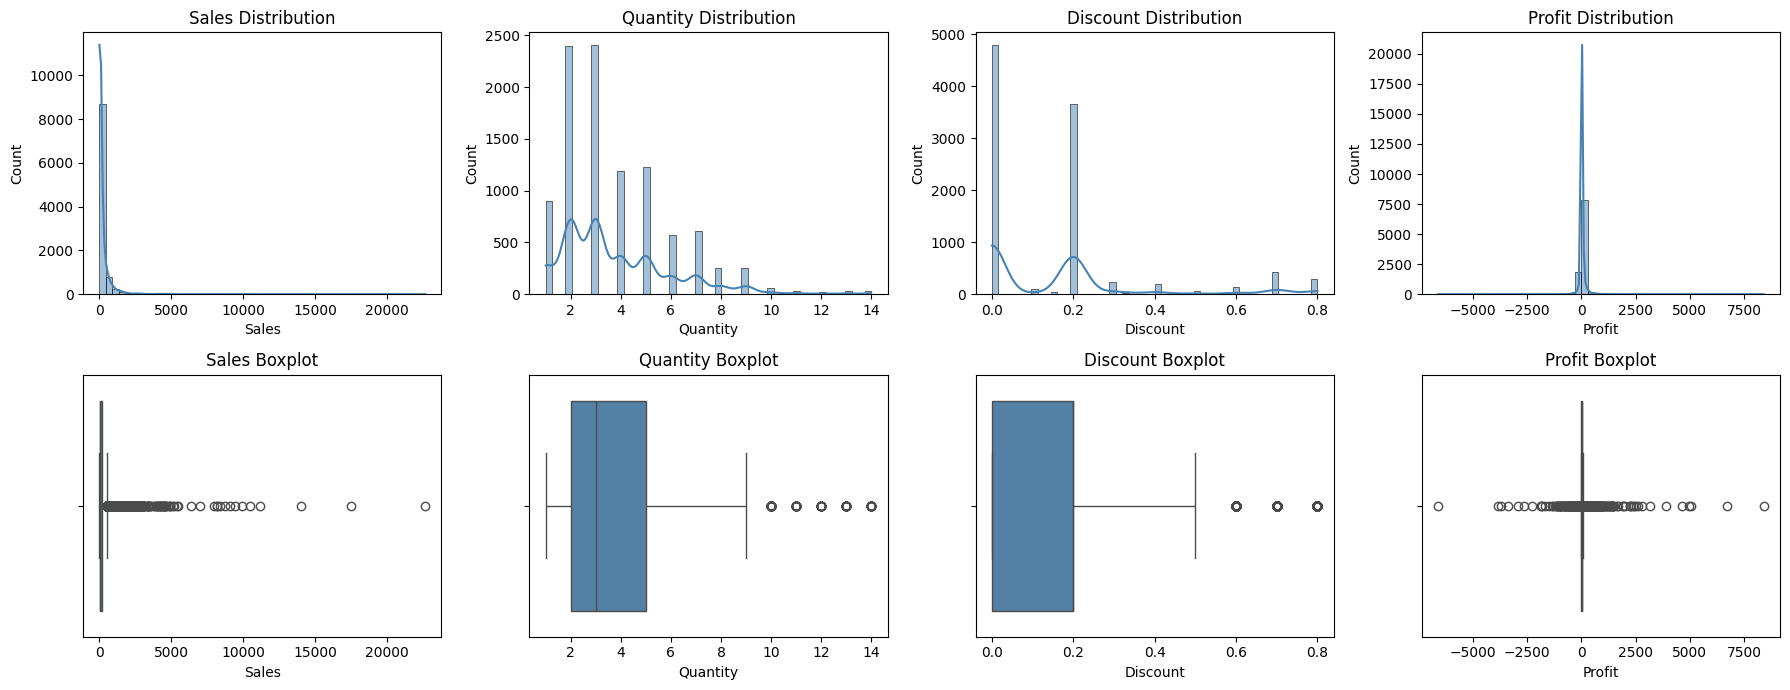

In [9]:
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit']

fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=50, color='steelblue', kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'{col} Distribution')
    
    sns.boxplot(x=df[col], color='steelblue', ax=axes[1, i])
    axes[1, i].set_title(f'{col} Boxplot')

plt.tight_layout()
plt.show()

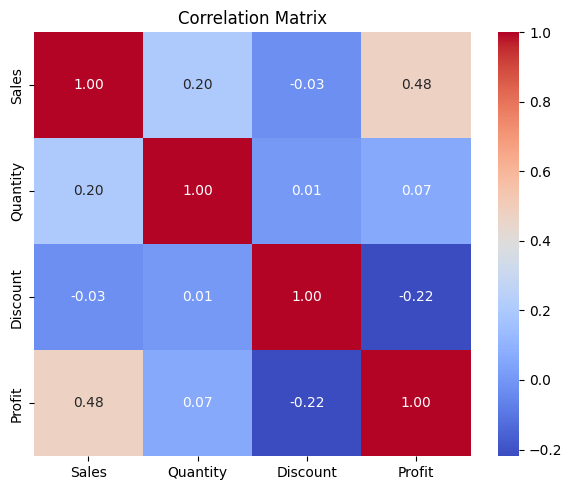

In [10]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [11]:
df.groupby('Segment')['Profit'].agg(['sum', 'mean']).sort_values('sum')

,sum,mean
Segment,,
Home Office,60298.6785,33.818664
Corporate,91979.1340,30.456667
Consumer,134119.2092,25.836873


In [12]:
segment_analysis = df.groupby('Segment').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

segment_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Segment,,,,,
Consumer,2586,1.161401e+06,134119.2092,25.836873,0.158141
Corporate,1514,7.061464e+05,91979.1340,30.456667,0.158228
Home Office,909,4.296531e+05,60298.6785,33.818664,0.147128


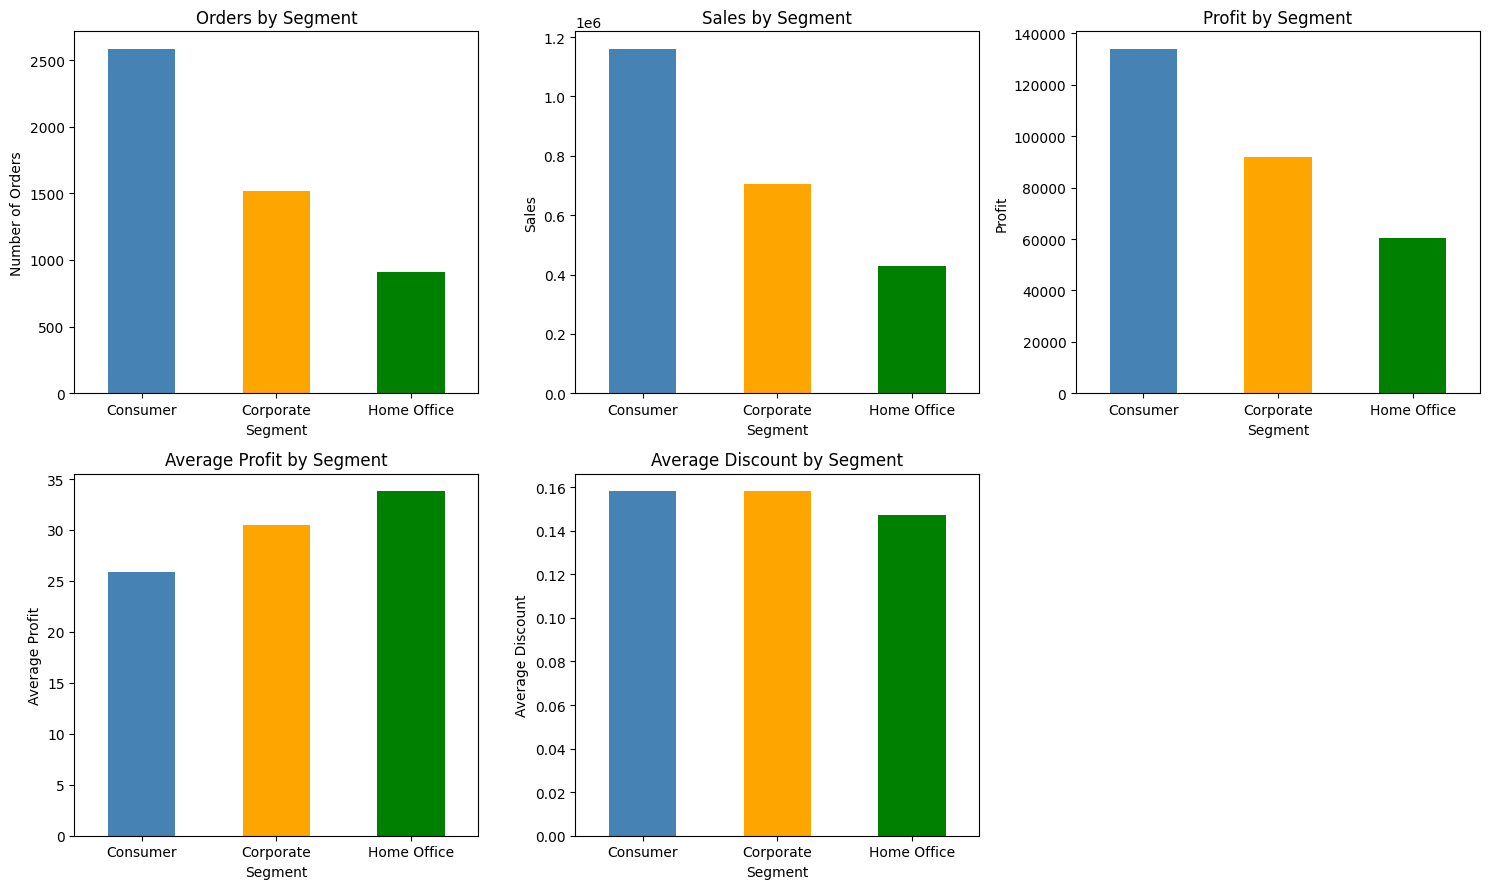

In [13]:
colors = ['steelblue', 'orange', 'green']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

segment_analysis['Orders'].plot(
    kind='bar',
    ax=axes[0, 0],
    color=colors
)
axes[0, 0].set_title('Orders by Segment')
axes[0, 0].set_ylabel('Number of Orders')
axes[0, 0].tick_params(axis='x', rotation=0)

segment_analysis['Sales'].plot(
    kind='bar',
    ax=axes[0, 1],
    color=colors
)
axes[0, 1].set_title('Sales by Segment')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=0)

segment_analysis['Profit'].plot(
    kind='bar',
    ax=axes[0, 2],
    color=colors
)
axes[0, 2].set_title('Profit by Segment')
axes[0, 2].set_ylabel('Profit')
axes[0, 2].tick_params(axis='x', rotation=0)

segment_analysis['Avg_Profit'].plot(
    kind='bar',
    ax=axes[1, 0],
    color=colors
)
axes[1, 0].set_title('Average Profit by Segment')
axes[1, 0].set_ylabel('Average Profit')
axes[1, 0].tick_params(axis='x', rotation=0)

segment_analysis['Avg_Discount'].plot(
    kind='bar',
    ax=axes[1, 1],
    color=colors
)
axes[1, 1].set_title('Average Discount by Segment')
axes[1, 1].set_ylabel('Average Discount')
axes[1, 1].tick_params(axis='x', rotation=0)

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## Segment Insights

* The **Consumer** segment has the highest number of orders, sales, and total profit.
* **Home Office** has the highest average profit per transaction, despite having the lowest order volume and sales among the three segments.
* Consumer and Corporate have very similar average discount levels, while Home Office has a lower average discount.

In [14]:
region_analysis = df.groupby('Region').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

region_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Region,,,,,
West,1611,725457.8245,108418.4489,33.849032,0.109335
East,1401,678781.2400,91522.7800,32.135808,0.145365
South,822,391721.9050,46749.4303,28.857673,0.147253
Central,1175,501239.8908,39706.3625,17.092709,0.240353


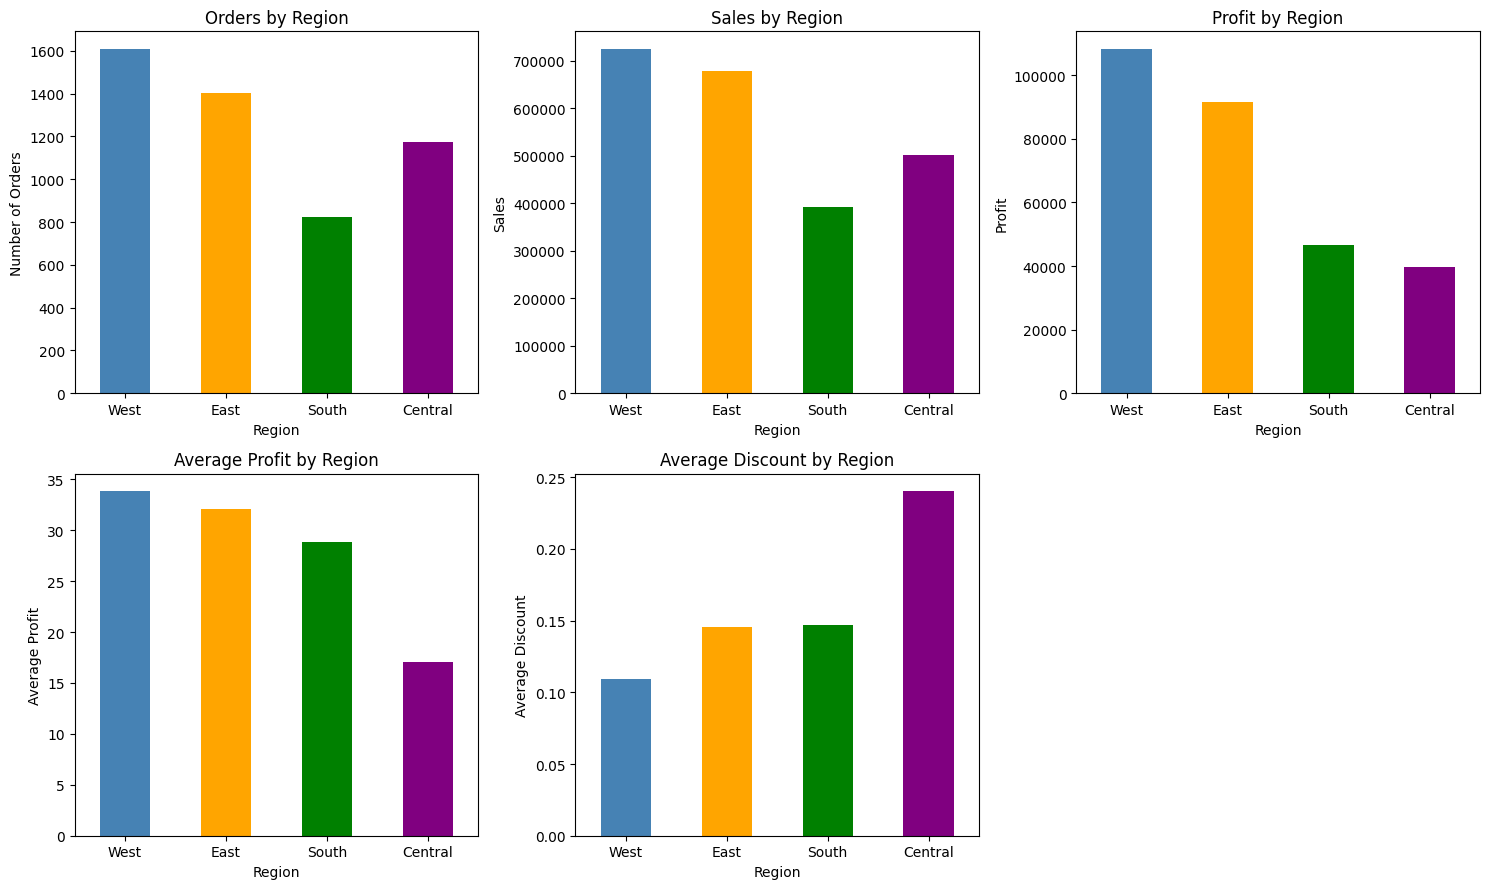

In [15]:
colors = ['steelblue', 'orange', 'green', 'purple']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

region_analysis['Orders'].plot(
    kind='bar',
    ax=axes[0, 0],
    color=colors
)
axes[0, 0].set_title('Orders by Region')
axes[0, 0].set_ylabel('Number of Orders')
axes[0, 0].tick_params(axis='x', rotation=0)

region_analysis['Sales'].plot(
    kind='bar',
    ax=axes[0, 1],
    color=colors
)
axes[0, 1].set_title('Sales by Region')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=0)

region_analysis['Profit'].plot(
    kind='bar',
    ax=axes[0, 2],
    color=colors
)
axes[0, 2].set_title('Profit by Region')
axes[0, 2].set_ylabel('Profit')
axes[0, 2].tick_params(axis='x', rotation=0)

region_analysis['Avg_Profit'].plot(
    kind='bar',
    ax=axes[1, 0],
    color=colors
)
axes[1, 0].set_title('Average Profit by Region')
axes[1, 0].set_ylabel('Average Profit')
axes[1, 0].tick_params(axis='x', rotation=0)

region_analysis['Avg_Discount'].plot(
    kind='bar',
    ax=axes[1, 1],
    color=colors
)
axes[1, 1].set_title('Average Discount by Region')
axes[1, 1].set_ylabel('Average Discount')
axes[1, 1].tick_params(axis='x', rotation=0)

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## Region Insights

* The **West** region has the highest orders, sales, and total profit.
* The **Central** region has the highest average discount but the lowest average profit and total profit among the regions.
* The South region has fewer orders and lower sales than the other regions, but its total profit is higher than Central.

In [16]:
category_analysis = df.groupby('Category').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

category_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Category,,,,,
Technology,1544,836154.0330,145454.9481,78.752002,0.132323
Office Supplies,3742,719047.0320,122490.8008,20.327050,0.157285
Furniture,1764,741999.7953,18451.2728,8.699327,0.173923


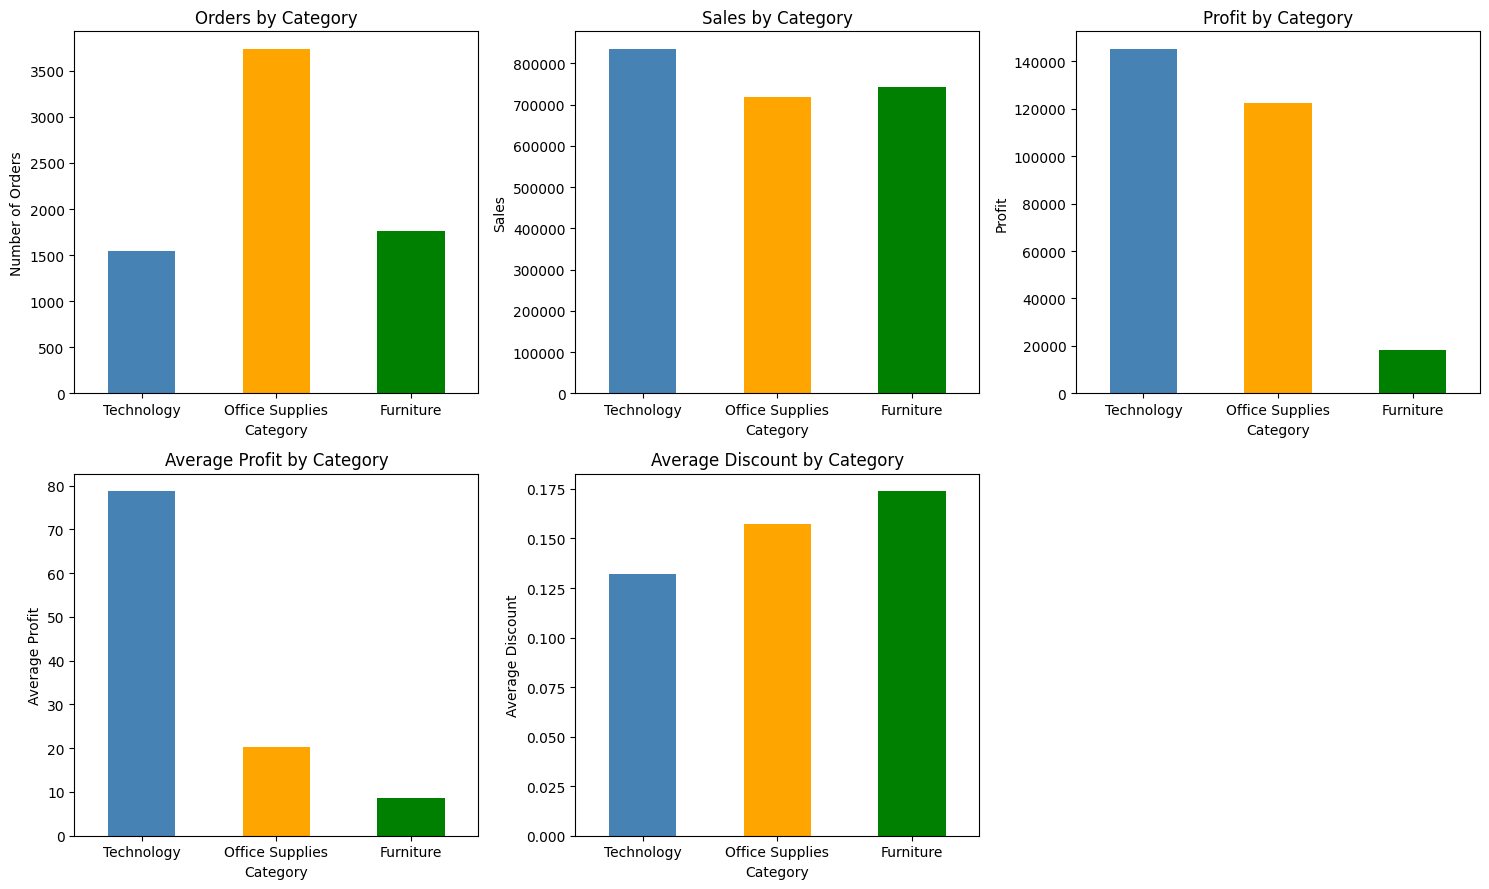

In [17]:
colors = ['steelblue', 'orange', 'green', 'purple']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

category_analysis['Orders'].plot(
    kind='bar',
    ax=axes[0, 0],
    color=colors
)
axes[0, 0].set_title('Orders by Category')
axes[0, 0].set_ylabel('Number of Orders')
axes[0, 0].tick_params(axis='x', rotation=0)

category_analysis['Sales'].plot(
    kind='bar',
    ax=axes[0, 1],
    color=colors
)
axes[0, 1].set_title('Sales by Category')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=0)

category_analysis['Profit'].plot(
    kind='bar',
    ax=axes[0, 2],
    color=colors
)
axes[0, 2].set_title('Profit by Category')
axes[0, 2].set_ylabel('Profit')
axes[0, 2].tick_params(axis='x', rotation=0)

category_analysis['Avg_Profit'].plot(
    kind='bar',
    ax=axes[1, 0],
    color=colors
)
axes[1, 0].set_title('Average Profit by Category')
axes[1, 0].set_ylabel('Average Profit')
axes[1, 0].tick_params(axis='x', rotation=0)

category_analysis['Avg_Discount'].plot(
    kind='bar',
    ax=axes[1, 1],
    color=colors
)
axes[1, 1].set_title('Average Discount by Category')
axes[1, 1].set_ylabel('Average Discount')
axes[1, 1].tick_params(axis='x', rotation=0)

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## Category Insights

* **Technology** generates the highest sales and total profit, despite having fewer orders than Office Supplies.
* **Office Supplies** has the highest number of orders but lower total sales and profit than Technology.
* **Furniture** generates relatively high sales but significantly lower profit, indicating that high sales volume does not necessarily mean high profitability.

In [18]:
ship_mode_analysis = df.groupby('Ship Mode').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

ship_mode_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Ship Mode,,,,,
Standard Class,2994,1.358216e+06,164088.7875,27.494770,0.160023
Second Class,964,4.591936e+05,57446.6354,29.535545,0.138895
First Class,787,3.514284e+05,48969.8399,31.839948,0.164610
Same Day,264,1.283631e+05,15891.7589,29.266591,0.152394


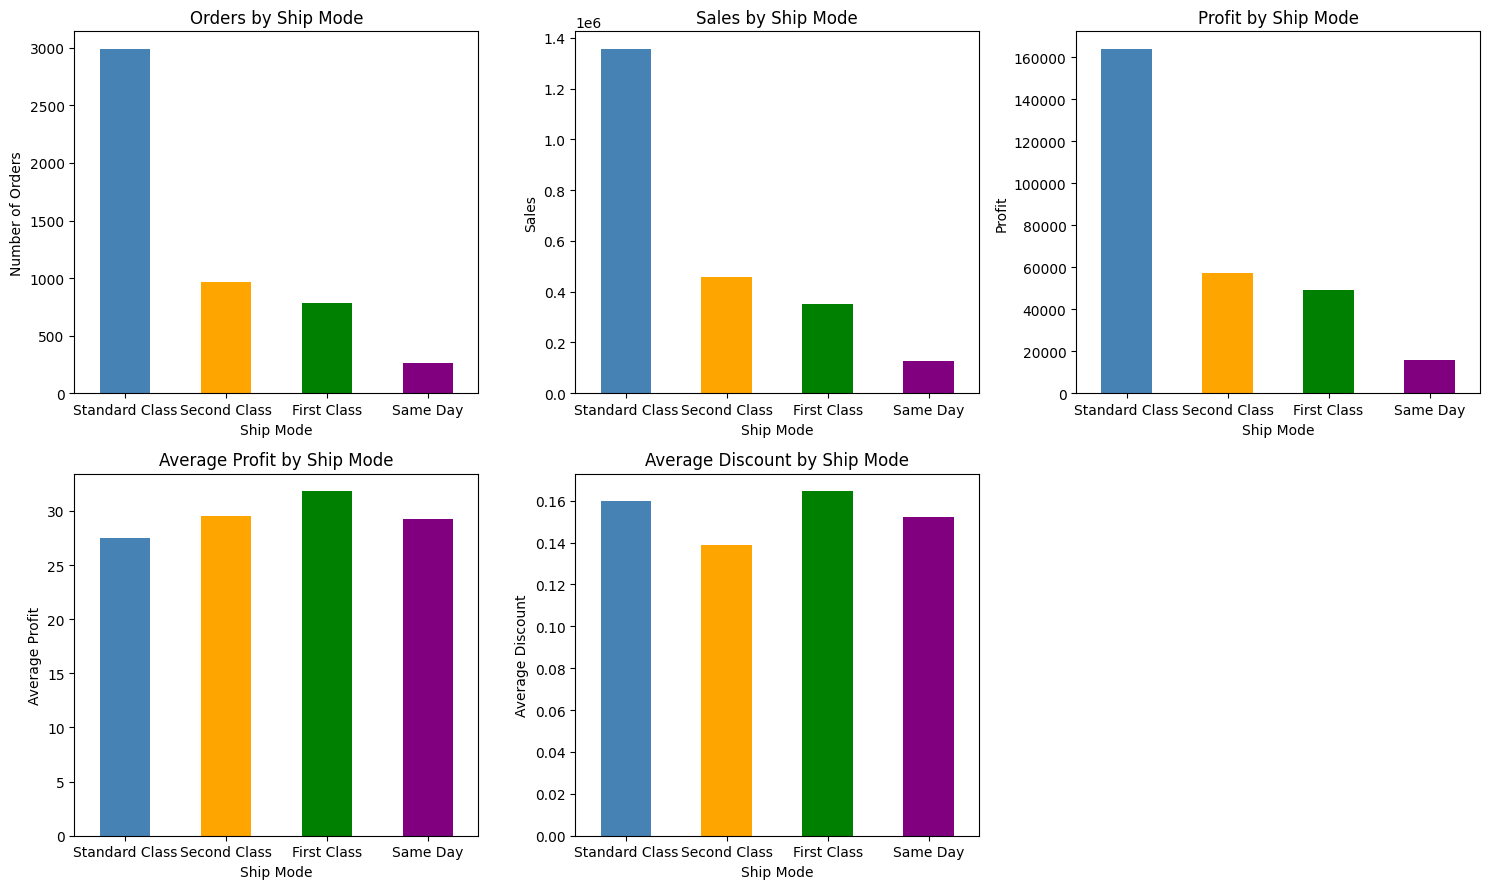

In [19]:
colors = ['steelblue', 'orange', 'green', 'purple']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

ship_mode_analysis['Orders'].plot(
    kind='bar',
    ax=axes[0, 0],
    color=colors
)
axes[0, 0].set_title('Orders by Ship Mode')
axes[0, 0].set_ylabel('Number of Orders')
axes[0, 0].tick_params(axis='x', rotation=0)

ship_mode_analysis['Sales'].plot(
    kind='bar',
    ax=axes[0, 1],
    color=colors
)
axes[0, 1].set_title('Sales by Ship Mode')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=0)

ship_mode_analysis['Profit'].plot(
    kind='bar',
    ax=axes[0, 2],
    color=colors
)
axes[0, 2].set_title('Profit by Ship Mode')
axes[0, 2].set_ylabel('Profit')
axes[0, 2].tick_params(axis='x', rotation=0)

ship_mode_analysis['Avg_Profit'].plot(
    kind='bar',
    ax=axes[1, 0],
    color=colors
)
axes[1, 0].set_title('Average Profit by Ship Mode')
axes[1, 0].set_ylabel('Average Profit')
axes[1, 0].tick_params(axis='x', rotation=0)

ship_mode_analysis['Avg_Discount'].plot(
    kind='bar',
    ax=axes[1, 1],
    color=colors
)
axes[1, 1].set_title('Average Discount by Ship Mode')
axes[1, 1].set_ylabel('Average Discount')
axes[1, 1].tick_params(axis='x', rotation=0)

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

In [20]:
sub_category_analysis = df.groupby('Sub-Category').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

sub_category_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Sub-Category,,,,,
Copiers,68,149528.0300,55617.8249,817.909190,0.161765
Phones,814,330007.0540,44515.7306,50.073938,0.154556
Accessories,718,167380.3180,41936.6357,54.111788,0.078452
Paper,1191,78479.2060,34053.5693,24.856620,0.074891
Binders,1316,203412.7330,30221.7633,19.843574,0.372292
Chairs,576,328449.1030,26590.1663,43.095894,0.170178
Storage,777,223843.6080,21278.8264,25.152277,0.074704
Appliances,451,107532.1610,18138.0054,38.922758,0.166524
Furnishings,877,91705.1640,13059.1436,13.645918,0.138349


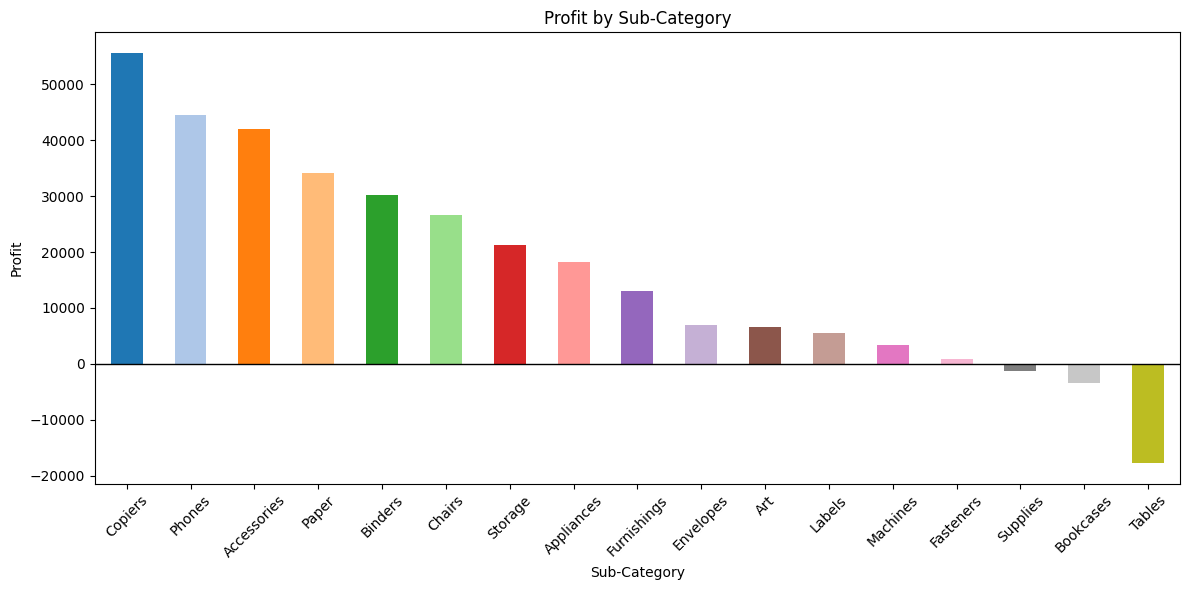

In [21]:
profit_sorted = sub_category_analysis.sort_values(
    'Profit',
    ascending=False
)

plt.figure(figsize=(12, 6))

profit_sorted['Profit'].plot(
    kind='bar',
    color=plt.cm.tab20(range(len(profit_sorted)))
)

plt.title('Profit by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.axhline(0, color='black', linewidth=1)

plt.tight_layout()
plt.show()

## 5. Sub-Category Insights

* **Copiers** generate the highest total profit and the highest average profit per transaction.
* **Phones** combine high sales, high order volume, and high total profit.
* **Tables, Bookcases, and Supplies** generate negative total profit.
* Some sub-categories with relatively high sales generate low or negative profit, highlighting the importance of evaluating profitability rather than sales alone.

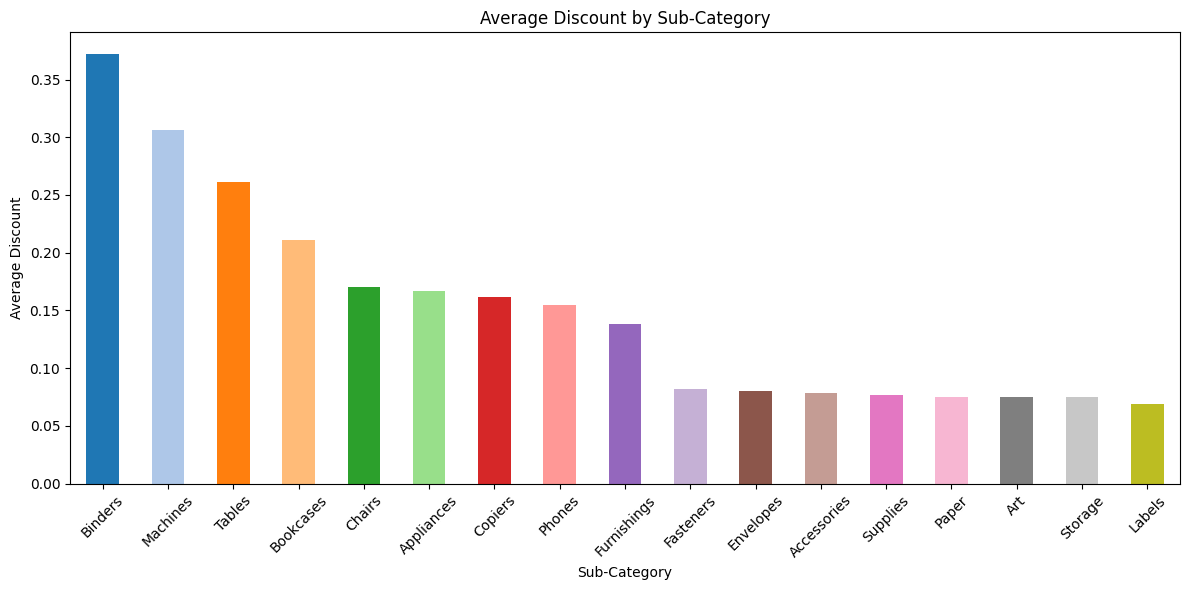

In [22]:
discount_sorted = sub_category_analysis.sort_values(
    'Avg_Discount',
    ascending=False
)

plt.figure(figsize=(12, 6))

discount_sorted['Avg_Discount'].plot(
    kind='bar',
    color=plt.cm.tab20(range(len(discount_sorted)))
)

plt.title('Average Discount by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Average Discount')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
discount_analysis = df.groupby('Discount').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
).sort_values('Discount', ascending=True)

discount_analysis

,Orders,Sales,Profit,Avg_Profit
Discount,,,,
0.00,2644,1.087908e+06,320987.6032,66.900292
0.10,89,5.436935e+04,9029.1770,96.055074
0.15,51,2.755852e+04,1418.9915,27.288298
0.20,2407,7.645944e+05,90337.3060,24.702572
0.30,211,1.032267e+05,-10369.2774,-45.679636
0.32,27,1.449346e+04,-2391.1377,-88.560656
0.40,185,1.164178e+05,-23057.0504,-111.927429
0.45,10,5.484974e+03,-2493.1111,-226.646464
0.50,64,5.891854e+04,-20506.4281,-310.703456


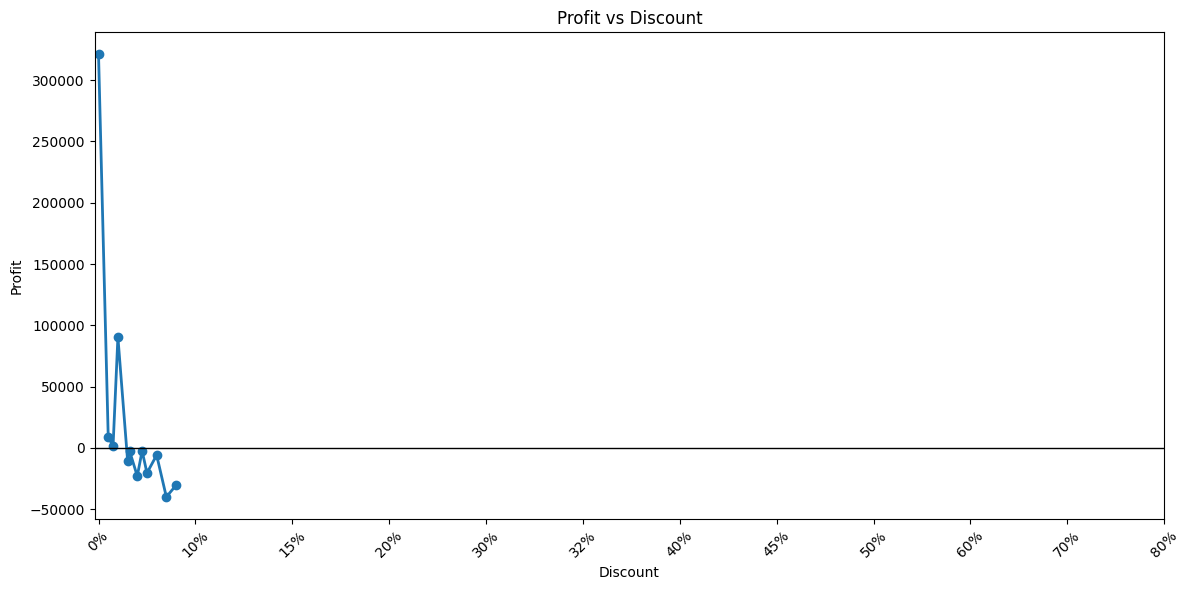

In [24]:
plt.figure(figsize=(12, 6))

discount_analysis['Profit'].plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Profit vs Discount')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.xticks(
    range(len(discount_analysis)),
    [f'{x:.0%}' for x in discount_analysis.index],
    rotation=45
)

plt.tight_layout()
plt.show()

## 6. Discount Insights

* Discount levels from **0% to 20%** are associated with positive total profit in this dataset.
* Discount levels of **30% or higher** are associated with negative total profit.
* Average profit generally decreases as discount levels become higher, although the relationship is not perfectly monotonic.
* These results show an association between discount levels and profitability, but they do not prove that higher discounts directly cause lower profits.

In [25]:
state_analysis = df.groupby('State').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

state_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
State,,,,,
California,1021,457687.6315,76381.3871,38.171608,0.072764
New York,562,310876.2710,74038.5486,65.637011,0.055319
Washington,256,138641.2700,33402.6517,66.013146,0.064032
Michigan,117,76269.6140,24463.1876,95.934069,0.007059
Virginia,115,70636.7200,18597.9504,83.026564,0.000000
Indiana,73,53555.3600,18382.9363,123.375411,0.000000
Georgia,91,49095.8400,16250.0433,88.315453,0.000000
Kentucky,61,36591.7500,11199.6966,80.573357,0.000000
Minnesota,44,29863.1500,10823.1874,121.608847,0.000000


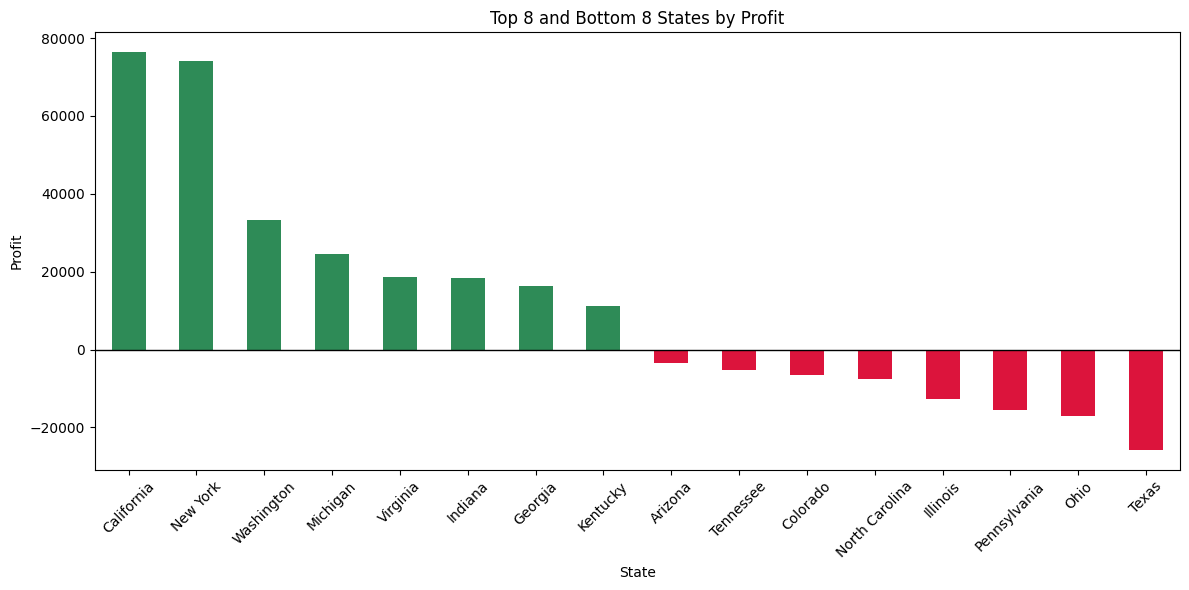

In [26]:
state_sorted = state_analysis.sort_values('Profit', ascending=False)
state_plot = pd.concat([state_sorted.head(8), state_sorted.tail(8)])

plt.figure(figsize=(12, 6))

state_plot['Profit'].plot(
    kind='bar',
    color=np.where(state_plot['Profit'] < 0, 'crimson', 'seagreen')
)

plt.title('Top 8 and Bottom 8 States by Profit')
plt.xlabel('State')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.axhline(0, color='black', linewidth=1)

plt.tight_layout()
plt.show()

In [27]:
product_analysis = df.groupby('Product Name').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Profit', ascending=False)

product_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Product Name,,,,,
Canon imageCLASS 2200 Advanced Copier,5,61599.824,25199.9280,5039.985600,0.120000
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,10,27453.384,7753.0390,775.303900,0.240000
Hewlett Packard LaserJet 3310 Copier,8,18839.686,6983.8836,872.985450,0.200000
Canon PC1060 Personal Laser Copier,4,11619.834,4570.9347,1142.733675,0.150000
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",3,18374.895,4094.9766,1364.992200,0.166667
...,...,...,...,...,...
Bush Advantage Collection Racetrack Conference Table,7,9544.725,-1934.3976,-276.342514,0.350000
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,5,9917.640,-2876.1156,-575.223120,0.280000
Cubify CubeX 3D Printer Triple Head Print,1,7999.980,-3839.9904,-3839.990400,0.500000


## Year Analysis

In [28]:
df['Year'] = df['Order Date'].dt.year
year_analysis = df.groupby('Year').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Avg_Discount=('Discount', 'mean')
).sort_index()

year_analysis

,Orders,Sales,Profit,Avg_Profit,Avg_Discount
Year,,,,,
2014,969,484247.4981,49543.9741,24.858994,0.158284
2015,1038,470532.5090,61618.6037,29.314274,0.155609
2016,1315,609205.5980,81795.1743,31.617771,0.154743
2017,1687,733215.2552,93439.2696,28.212340,0.156467


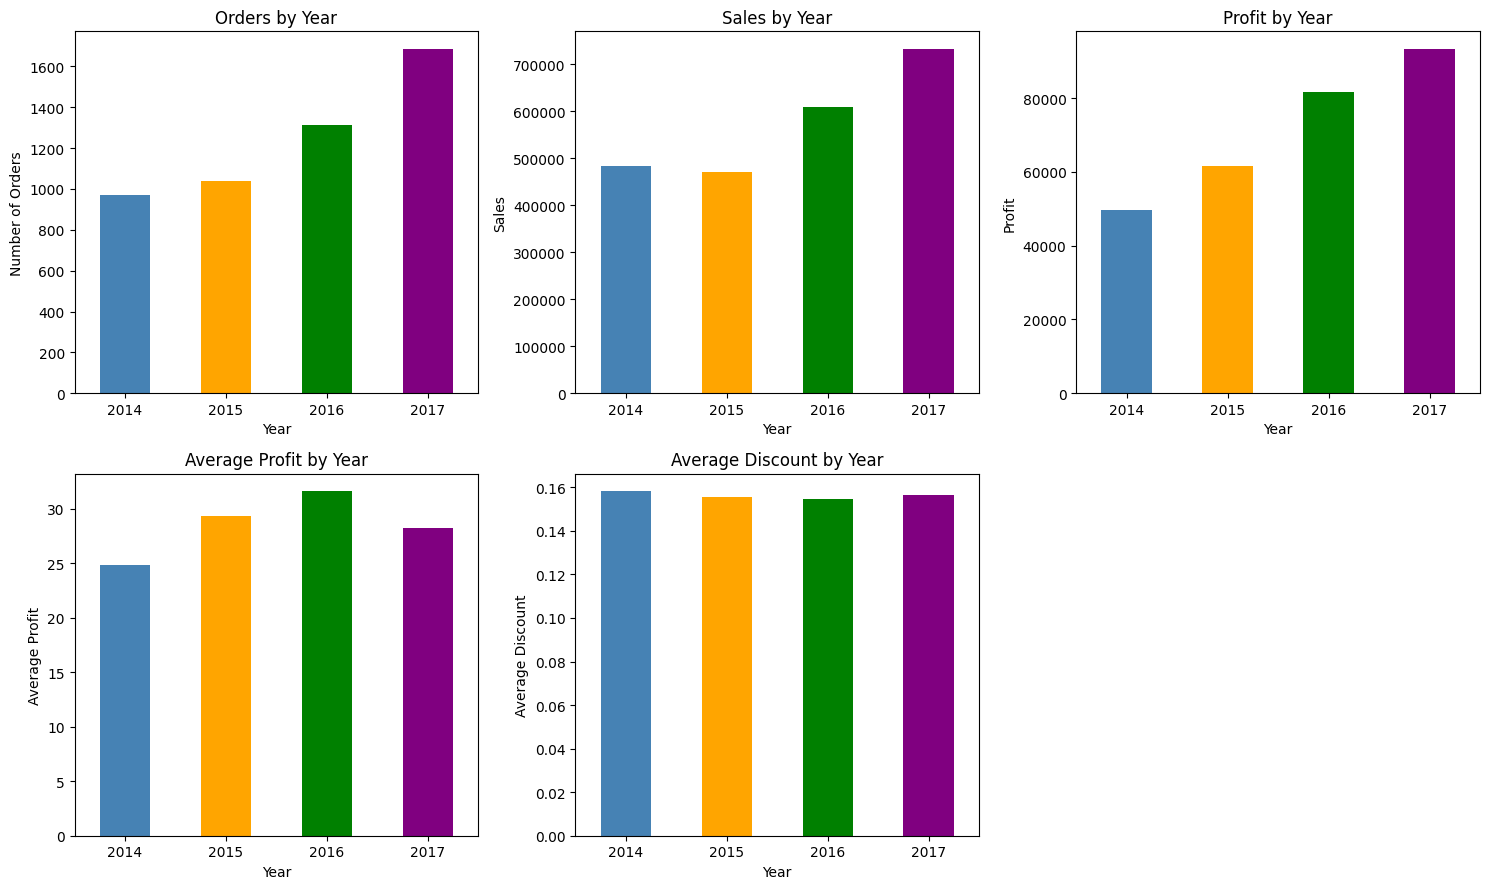

In [29]:
colors = ['steelblue', 'orange', 'green', 'purple']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

year_analysis['Orders'].plot(
    kind='bar',
    ax=axes[0, 0],
    color=colors
)
axes[0, 0].set_title('Orders by Year')
axes[0, 0].set_ylabel('Number of Orders')
axes[0, 0].tick_params(axis='x', rotation=0)

year_analysis['Sales'].plot(
    kind='bar',
    ax=axes[0, 1],
    color=colors
)
axes[0, 1].set_title('Sales by Year')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=0)

year_analysis['Profit'].plot(
    kind='bar',
    ax=axes[0, 2],
    color=colors
)
axes[0, 2].set_title('Profit by Year')
axes[0, 2].set_ylabel('Profit')
axes[0, 2].tick_params(axis='x', rotation=0)

year_analysis['Avg_Profit'].plot(
    kind='bar',
    ax=axes[1, 0],
    color=colors
)
axes[1, 0].set_title('Average Profit by Year')
axes[1, 0].set_ylabel('Average Profit')
axes[1, 0].tick_params(axis='x', rotation=0)

year_analysis['Avg_Discount'].plot(
    kind='bar',
    ax=axes[1, 1],
    color=colors
)
axes[1, 1].set_title('Average Discount by Year')
axes[1, 1].set_ylabel('Average Discount')
axes[1, 1].tick_params(axis='x', rotation=0)

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Year Insights

* The number of orders increased consistently from **2014 to 2017**.
* Sales increased overall, from approximately **484K in 2014** to **733K in 2017**.
* Total profit also increased every year, reaching its highest level in **2017**.
* **2016** had the highest average profit per transaction, while 2017 had higher total profit due to greater overall business activity.

In [30]:
df['Month_Name'] = df['Order Date'].dt.month_name()
month_analysis = df.groupby('Month_Name').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean')
).sort_index()

month_analysis

,Orders,Sales,Profit,Avg_Profit
Month_Name,,,,
April,343,137762.1286,11587.4363,17.346462
August,341,159044.0630,21776.9384,30.845522
December,702,325293.5035,43369.1919,30.801983
February,162,59751.2514,10294.6107,34.315369
January,178,94924.8356,9134.4461,23.974924
July,338,147238.0970,13832.6648,19.482626
June,364,152718.6793,21285.7954,29.687302
March,354,205005.4888,28594.6872,41.084321
May,369,155028.8117,22411.3078,30.491575


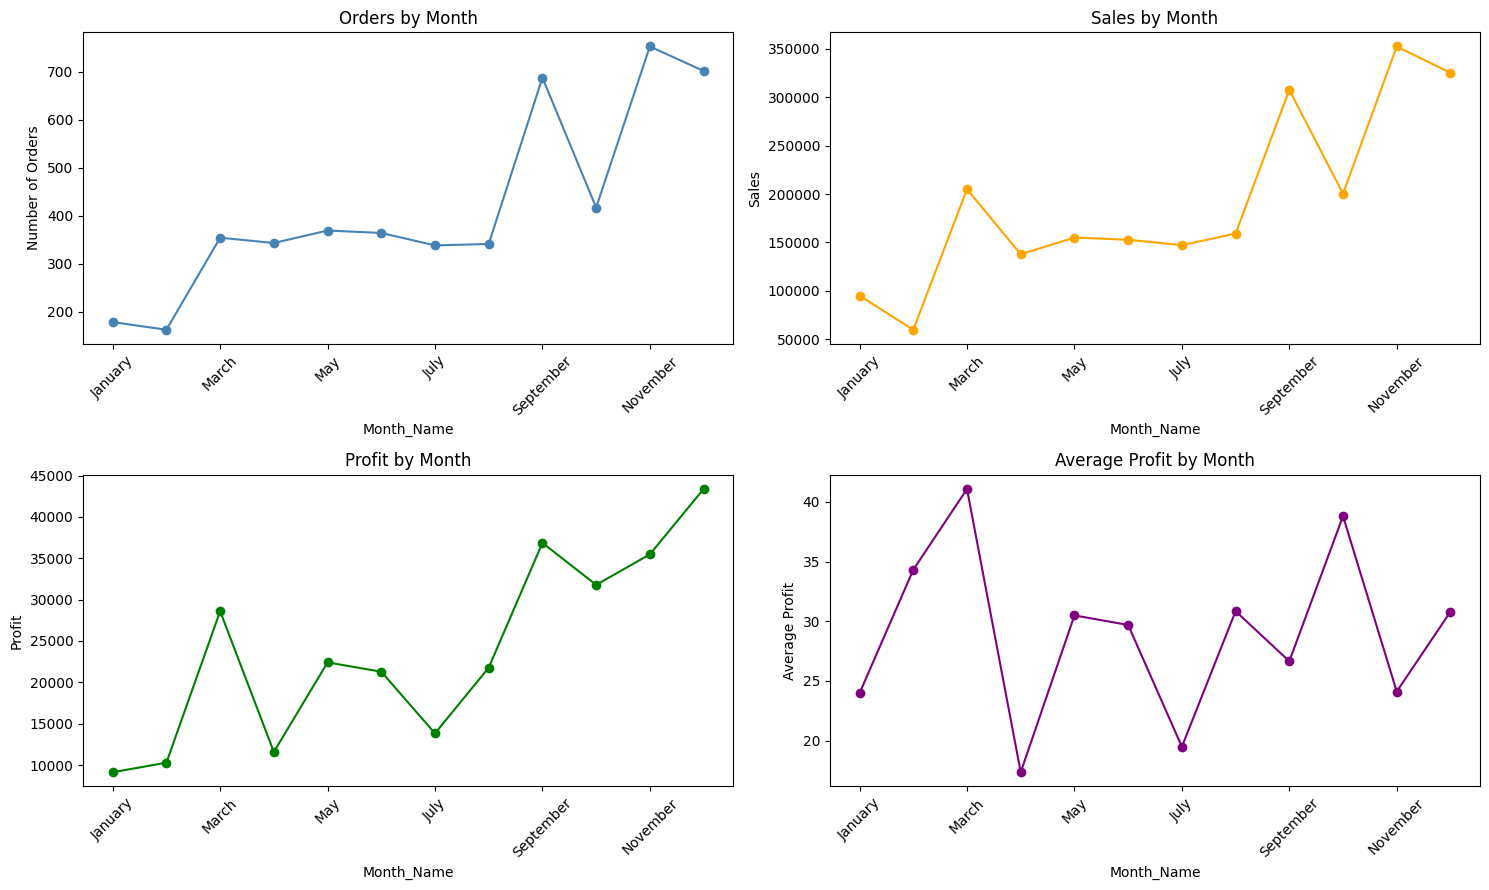

In [31]:
# Order months correctly
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

month_analysis = month_analysis.reindex(month_order)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

month_analysis['Orders'].plot(
    kind='line',
    marker='o',
    ax=axes[0, 0],
    color='steelblue'
)
axes[0, 0].set_title('Orders by Month')
axes[0, 0].set_ylabel('Number of Orders')
axes[0, 0].tick_params(axis='x', rotation=45)


month_analysis['Sales'].plot(
    kind='line',
    marker='o',
    ax=axes[0, 1],
    color='orange'
)
axes[0, 1].set_title('Sales by Month')
axes[0, 1].set_ylabel('Sales')
axes[0, 1].tick_params(axis='x', rotation=45)


month_analysis['Profit'].plot(
    kind='line',
    marker='o',
    ax=axes[1, 0],
    color='green'
)
axes[1, 0].set_title('Profit by Month')
axes[1, 0].set_ylabel('Profit')
axes[1, 0].tick_params(axis='x', rotation=45)


month_analysis['Avg_Profit'].plot(
    kind='line',
    marker='o',
    ax=axes[1, 1],
    color='purple'
)
axes[1, 1].set_title('Average Profit by Month')
axes[1, 1].set_ylabel('Average Profit')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Month Insights

* **December** has the highest sales and total profit.
* **November** has the highest number of orders.
* **March** has the highest average profit per transaction.
* January and April have relatively low total profit compared with the stronger-performing months.

# Final Business Insights

## Overall Performance

* The business shows overall positive profitability, with differences in performance across segments, regions, categories, and time periods.
* Sales volume and profit are not always directly aligned, so profitability should be considered alongside sales and order volume.

## Key Business Takeaways

* **Sales volume alone is not enough to evaluate business performance; profitability should always be considered.**
* High-performing areas such as **Technology, Consumer, and West** contribute strongly to total business performance.
* Products with negative profitability require further investigation.
* High discount levels are associated with lower profitability in this dataset and should therefore be monitored carefully.
* The difference between **total profit** and **average profit** is important: a segment or period can generate high total profit because of high volume while having a lower profit per transaction.
* Business performance varies considerably across customers, regions, products, discount levels, and time periods, so these factors should be considered together when making business decisions.


## Additional EDA: What Drives Profit?

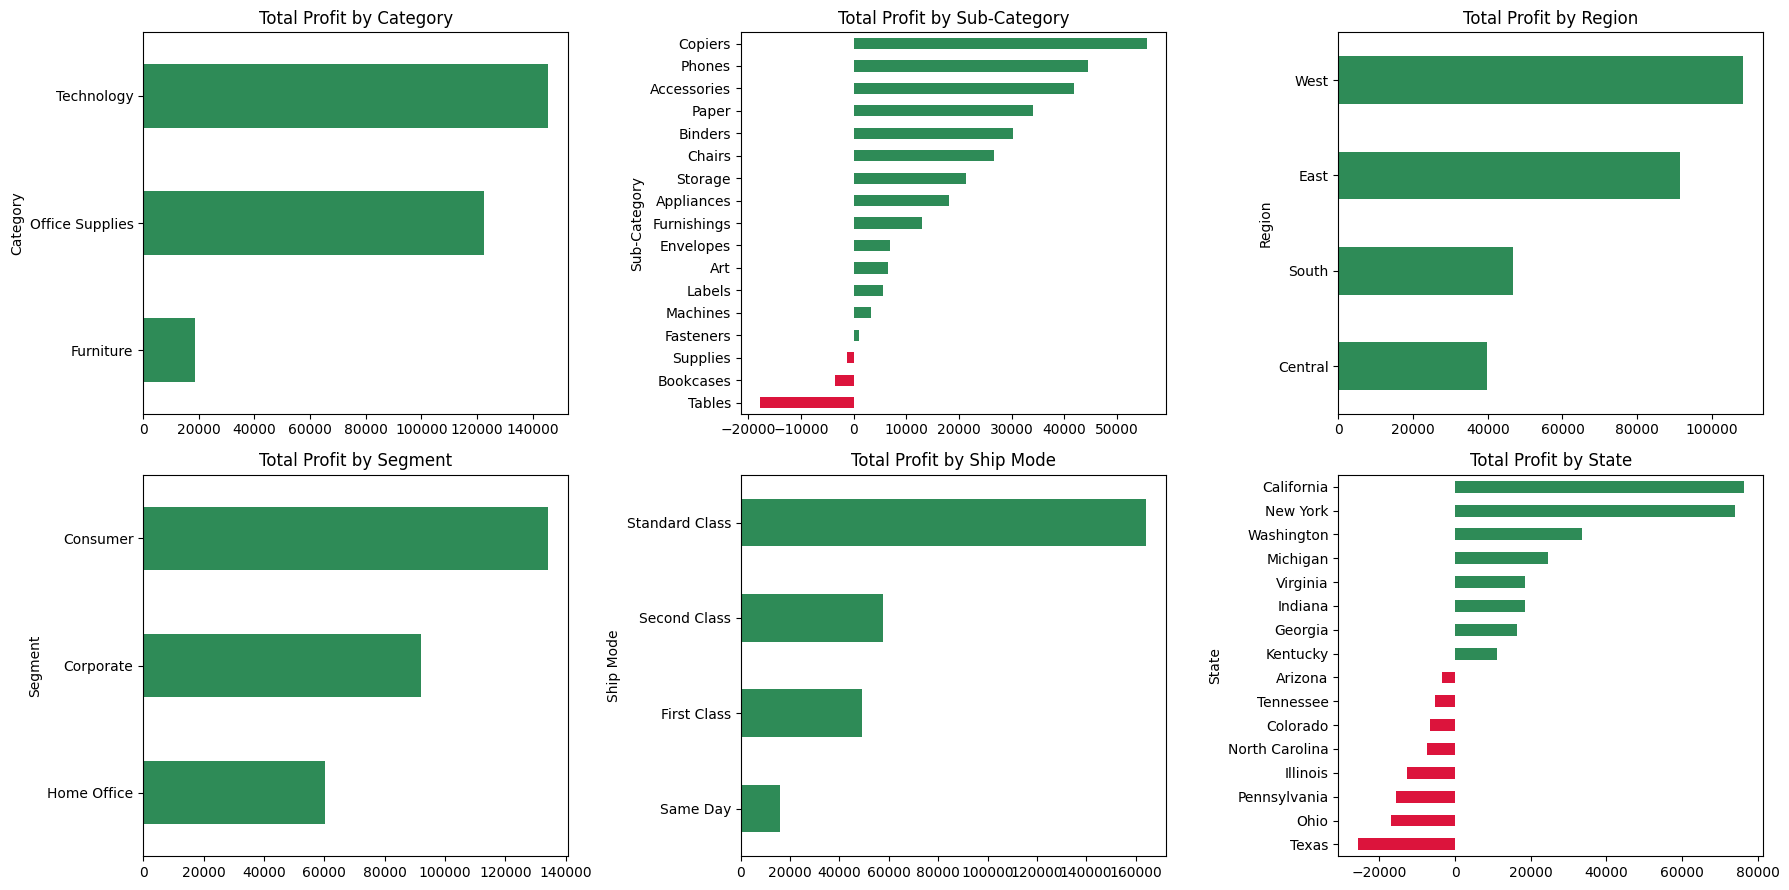

In [32]:
# Total profit by group (red = loss-making)
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, c in zip(ax.ravel(), ["Category", "Sub-Category", "Region", "Segment", "Ship Mode", "State"]):
    g = df.groupby(c).Profit.sum().sort_values()
    if c == "State": g = pd.concat([g.head(8), g.tail(8)])
    g.plot.barh(ax=a, color=np.where(g < 0, "crimson", "seagreen")); a.set_title(f"Total Profit by {c}")
plt.tight_layout(); plt.show()

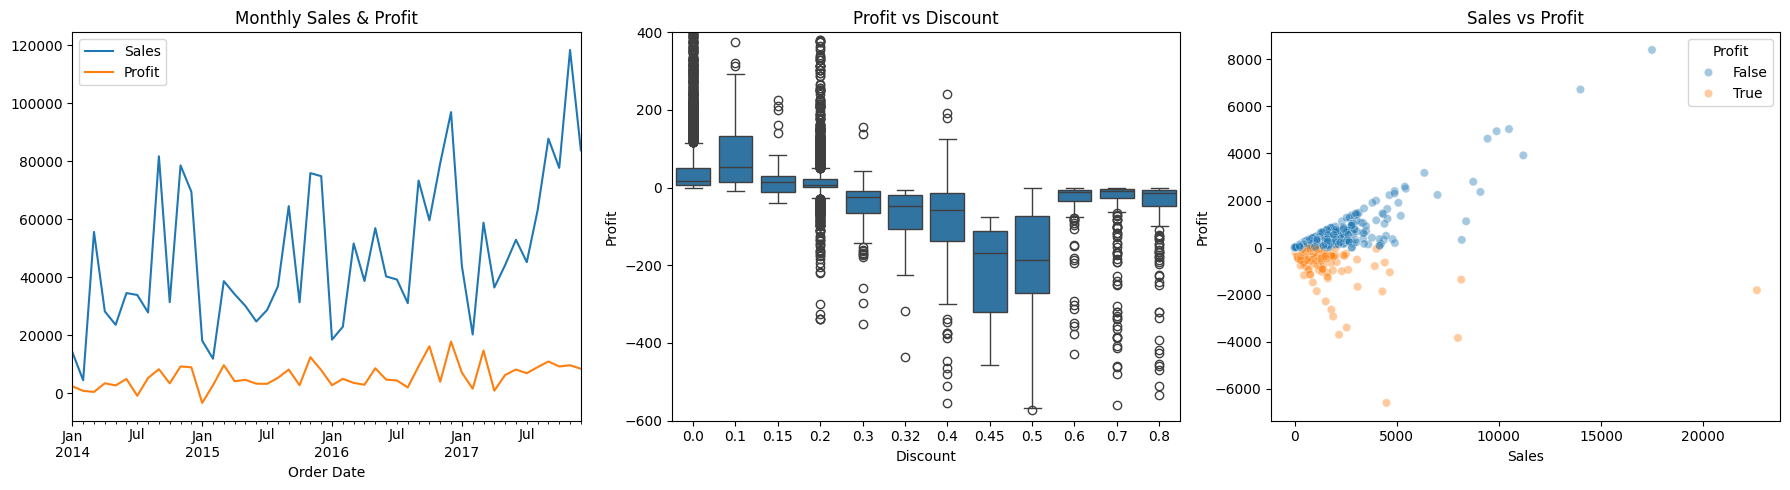

Average profit by discount level:


Discount,0.00,0.10,0.15,0.20,0.30,0.32,0.40,0.45,0.50,0.60,0.70,0.80
avg_profit,66.9,96.06,27.29,24.7,-45.68,-88.56,-111.93,-226.65,-310.7,-43.08,-95.87,-101.8


Total profit by Sub-Category:


Sub-Category,Tables,Bookcases,Supplies,Fasteners,Machines,Labels,Art,Envelopes,Furnishings,Appliances,Storage,Chairs,Binders,Paper,Accessories,Phones,Copiers
total_profit,-17725.0,-3473.0,-1189.0,950.0,3385.0,5546.0,6528.0,6964.0,13059.0,18138.0,21279.0,26590.0,30222.0,34054.0,41937.0,44516.0,55618.0


In [33]:
# Time trend + discount effect
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
m = df.groupby(df["Order Date"].dt.to_period("M"))[["Sales", "Profit"]].sum()
m.index = m.index.to_timestamp(); m.plot(ax=ax[0], title="Monthly Sales & Profit")
sns.boxplot(data=df, x="Discount", y="Profit", ax=ax[1]); ax[1].set_ylim(-600, 400); ax[1].set_title("Profit vs Discount")
sns.scatterplot(data=df, x="Sales", y="Profit", hue=df.Profit < 0, alpha=.4, ax=ax[2]); ax[2].set_title("Sales vs Profit")
plt.tight_layout(); plt.show()

print("Average profit by discount level:"); display(df.groupby("Discount").Profit.mean().round(2).to_frame("avg_profit").T)
print("Total profit by Sub-Category:"); display(df.groupby("Sub-Category").Profit.sum().round(0).sort_values().to_frame("total_profit").T)

## Preprocessing

In [34]:
df['ShipDays'] = (df['Ship Date'] - df['Order Date']).dt.days
df['DayOfWeek'] = df['Order Date'].dt.dayofweek
df['Quarter'] = df['Order Date'].dt.quarter
df['Month'] = df['Order Date'].dt.month
df['UnitPrice'] = df['Sales'] / df['Quantity'] / (1 - df['Discount'])
df['LogSales'] = np.log1p(df['Sales'])

In [35]:
df['Is_Loss'] = (df['Profit'] < 0).astype(int)

In [36]:
target = 'Profit'
target_class = 'Is_Loss'

In [37]:
features = [
    'Segment',
    'Ship Mode',
    'State',
    'Region',
    'Category',
    'Sub-Category',
    'Sales',
    'Quantity',
    'Discount',
    'DayOfWeek',
    'Quarter',
    'Month',
    'Year',
    'UnitPrice',
    'LogSales'
]

**Feature note.** `ShipDays` is created for EDA only and is *not* used as a model feature, because the ship date is not known when an order is placed.
`Sales`, `UnitPrice` and `LogSales` are known at order time (they come from the catalog price, quantity and discount), so they are valid features for predicting `Profit`.

In [38]:
X = df[features]
y = df[target]
y_class = df[target_class]

In [39]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Segment       9994 non-null   str    
 1   Ship Mode     9994 non-null   str    
 2   State         9994 non-null   str    
 3   Region        9994 non-null   str    
 4   Category      9994 non-null   str    
 5   Sub-Category  9994 non-null   str    
 6   Sales         9994 non-null   float64
 7   Quantity      9994 non-null   int64  
 8   Discount      9994 non-null   float64
 9   DayOfWeek     9994 non-null   int32  
 10  Quarter       9994 non-null   int32  
 11  Month         9994 non-null   int32  
 12  Year          9994 non-null   int32  
 13  UnitPrice     9994 non-null   float64
 14  LogSales      9994 non-null   float64
dtypes: float64(4), int32(4), int64(1), str(6)
memory usage: 1015.1 KB


In [40]:
X.isnull().sum()

Segment         0
Ship Mode       0
State           0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
DayOfWeek       0
Quarter         0
Month           0
Year            0
UnitPrice       0
LogSales        0
dtype: int64

In [41]:
X.head()

,Segment,Ship Mode,State,Region,Category,Sub-Category,Sales,Quantity,Discount,DayOfWeek,Quarter,Month,Year,UnitPrice,LogSales
0,Consumer,Second Class,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,1,4,11,2016,130.98,5.572002
1,Consumer,Second Class,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,1,4,11,2016,243.98,6.597064
2,Corporate,Second Class,California,West,Office Supplies,Labels,14.6200,2,0.00,6,2,6,2016,7.31,2.748552
3,Consumer,Standard Class,Florida,South,Furniture,Tables,957.5775,5,0.45,6,4,10,2015,348.21,6.865450
4,Consumer,Standard Class,Florida,South,Office Supplies,Storage,22.3680,2,0.20,6,4,10,2015,13.98,3.151368


In [42]:
X_train, X_test, y_train, y_test, y_class_train, y_class_test = train_test_split(
    X, y, y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

In [43]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("Loss rate train:", round(y_class_train.mean(), 3))
print("Loss rate test :", round(y_class_test.mean(), 3))

X_train: (7995, 15)
X_test : (1999, 15)
y_train: (7995,)
y_test : (1999,)
Loss rate train: 0.187
Loss rate test : 0.187


In [44]:
categorical_features = ['Segment','Ship Mode','State','Region','Category','Sub-Category']

In [45]:
numerical_features = ['Sales','Quantity','Discount','DayOfWeek','Quarter','Month','Year','UnitPrice','LogSales']

In [46]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10, sparse_output=False), categorical_features)
    ]
)

In [47]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [48]:
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (7995, 85)
X_test_processed shape: (1999, 85)


In [49]:
feature_names = preprocessor.get_feature_names_out()

## Models training

#### Linear Regression

In [50]:
model = LinearRegression()
model.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [51]:
y_pred_lr = model.predict(X_test_processed)

#### Decision Tree

In [52]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_processed, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_l

In [53]:
y_pred_dt = dt_model.predict(X_test_processed)

#### Random Forest

In [54]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_jobs=-1,random_state=42)
rf_model.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [55]:
y_pred_rf = rf_model.predict(X_test_processed)

#### HistGradient Boosting

In [56]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(random_state=42)
hgb_model.fit(X_train_processed, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 

In [57]:
y_pred_hgb = hgb_model.predict(X_test_processed)

#### Models Evaluation

In [58]:
base_results = []

models_predictions = {
    "Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "HistGradientBoosting": y_pred_hgb
}

for model_name, y_pred in models_predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    base_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

base_results_df = pd.DataFrame(base_results)
base_results_df = base_results_df.sort_values(
        by="R²", 
        ascending=False
    ).reset_index(drop=True)
base_results_df


,Model,MAE,MSE,RMSE,R²
0,Random Forest,18.062633,7974.396312,89.299475,0.849844
1,HistGradientBoosting,21.621420,13005.428388,114.041345,0.755110
2,Linear Regression,61.644975,24720.462358,157.227422,0.534518
3,Decision Tree,28.117165,44235.652272,210.322734,0.167051


In [59]:
best_base_model = base_results_df.iloc[0]
print("Best Base Model:")
print(best_base_model)

Best Base Model:
Model    Random Forest
MAE          18.062633
MSE        7974.396312
RMSE         89.299475
R²            0.849844
Name: 0, dtype: object


## Hyperparameter Tunning for best model 

In [60]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    "n_estimators": [100, 200],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": [0.3, 0.5, 0.8, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
    param_distributions=rf_param_dist,
    n_iter=6,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train_processed, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 12, ...], 'max_features': [0.3, 0.5, ...], 'min_samples_leaf': [1, 3, ...], 'n_estimators': [100, 200]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",6
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versioncha

In [61]:
print("Best Parameters:", rf_search.best_params_)
print("Best CV R²:", rf_search.best_score_)

Best Parameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 12}
Best CV R²: 0.4219667215252147


In [62]:
best_rf = rf_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test_processed)

###  Evaluate the Tuned Random Forest


In [63]:
mae_best_rf = mean_absolute_error(y_test, y_pred_best_rf)
mse_best_rf = mean_squared_error(y_test, y_pred_best_rf)
rmse_best_rf = np.sqrt(mse_best_rf)
r2_best_rf = r2_score(y_test, y_pred_best_rf)

print("Tuned Random Forest Results")
print("MAE :", mae_best_rf)
print("MSE :", mse_best_rf)
print("RMSE:", rmse_best_rf)
print("R²  :", r2_best_rf)

Tuned Random Forest Results
MAE : 20.967906608786134
MSE : 6661.146027469205
RMSE: 81.61584421832077
R²  : 0.8745718603217784


### Base Random Forest vs Tuned Random Forest

In [64]:
rf_comparison = pd.DataFrame({
    "Model": [
        "Base Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_rf),
        mae_best_rf
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        rmse_best_rf
    ],
    "R²": [
        r2_score(y_test, y_pred_rf),
        r2_best_rf
    ]
})

rf_comparison


,Model,MAE,RMSE,R²
0,Base Random Forest,18.062633,89.299475,0.849844
1,Tuned Random Forest,20.967907,81.615844,0.874572


### Train vs Test Performance

In [65]:
y_train_pred_rf = best_rf.predict(X_train_processed)

train_r2_rf = r2_score(y_train, y_train_pred_rf)
test_r2_rf = r2_score(y_test, y_pred_best_rf)

print("Train R²:", train_r2_rf)
print("Test R² :", test_r2_rf)

Train R²: 0.9413968090391731
Test R² : 0.8745718603217784


###  Final Model — Actual vs Predicted and Residuals

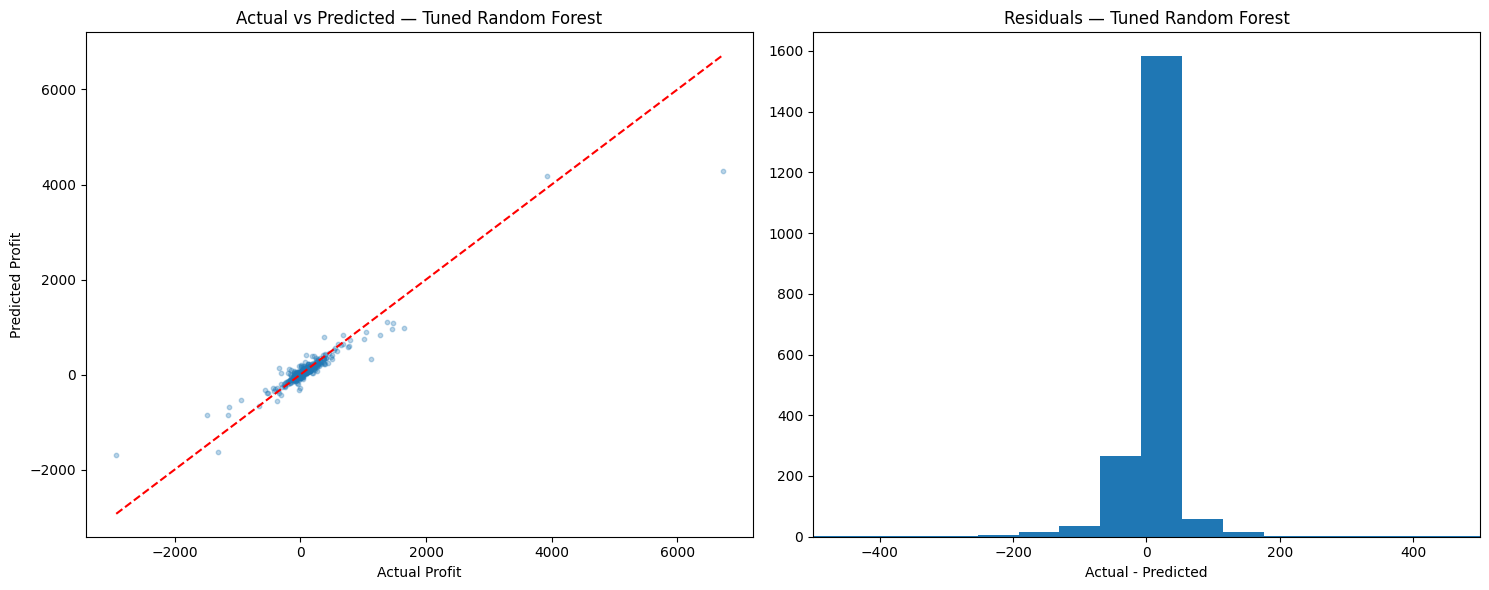

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(y_test, y_pred_best_rf, alpha=0.3, s=10)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[0].set_title("Actual vs Predicted — Tuned Random Forest")
axes[0].set_xlabel("Actual Profit")
axes[0].set_ylabel("Predicted Profit")

residuals = y_test - y_pred_best_rf

axes[1].hist(residuals, bins=60)
axes[1].set_title("Residuals — Tuned Random Forest")
axes[1].set_xlabel("Actual - Predicted")
axes[1].set_xlim(-500, 500)

plt.tight_layout()
plt.show()


###  Permutation Feature Importance

In [67]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_rf,
    X_test_processed,
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
    scoring='r2'
)

importance = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)
importance.head(10)

num__Discount                    0.414736
num__LogSales                    0.331600
num__Sales                       0.273012
num__UnitPrice                   0.114335
cat__Sub-Category_Copiers        0.070947
cat__Sub-Category_Binders        0.016956
num__Quantity                    0.008162
cat__Category_Technology         0.007626
cat__State_Texas                 0.005203
cat__Category_Office Supplies    0.004793
dtype: float64

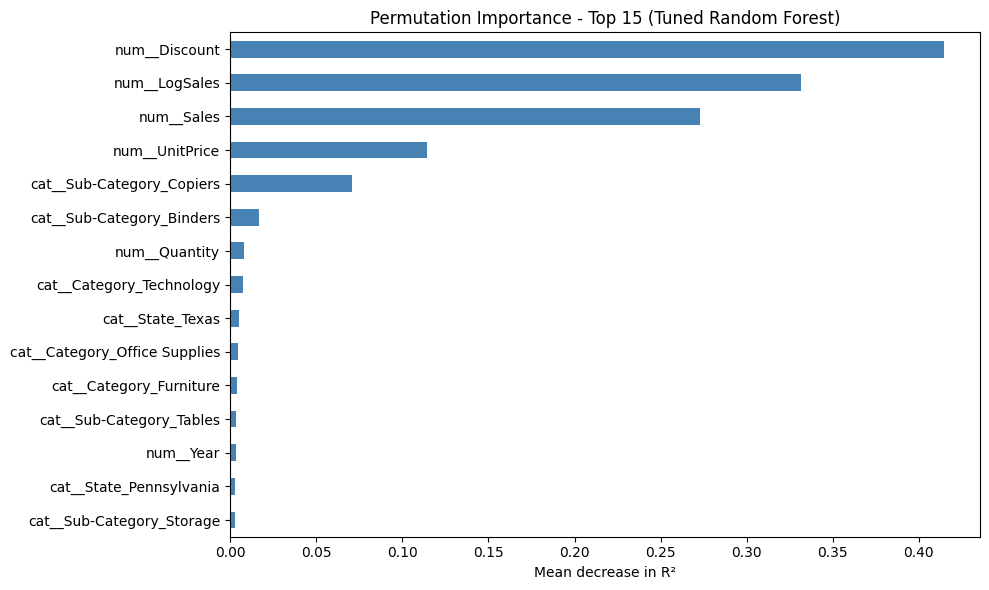

In [68]:
best_reg_name = "Tuned Random Forest"
plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title(f'Permutation Importance - Top 15 ({best_reg_name})')
plt.xlabel('Mean decrease in R²')

plt.tight_layout()
plt.show()

# Classification — Will the Order Result in a Loss?

**Goal:** Classify each order as **Loss** (`Profit < 0`) or **Profit**.

**Why it matters:** Predicting a loss before an order is fulfilled supports discount and pricing decisions. It is also more stable than predicting the exact profit value, which has large outliers

## 1) Target Definition and Class Balance

- `Is_Loss = 1` if `Profit < 0`, otherwise `0`.
- Loss orders make up about **18.7%** of the data, so the dataset is **imbalanced**.

**Impact on the approach:**
- Logistic Regression and Random Forest use `class_weight="balanced"` so they don't ignore losses (HistGradientBoosting is used with default weights).
- We rely on **F1 / Recall / ROC-AUC**, not Accuracy alone. A model that predicts "profit" for everything would still score about 81% Accuracy without catching a single loss.

## Models Training

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay

In [70]:
models_res=[]

### Logistic Regression

In [71]:
logreg_model = LogisticRegression(max_iter=2000, class_weight='balanced')

logreg_model.fit(X_train_processed, y_class_train)

y_pred_logreg = logreg_model.predict(X_test_processed)
y_prob_logreg = logreg_model.predict_proba(X_test_processed)[:, 1]

#### Evaluate LogisticRegression

In [72]:
acc_logreg = accuracy_score(y_class_test, y_pred_logreg)
f1_logreg = f1_score(y_class_test, y_pred_logreg)
auc_logreg = roc_auc_score(y_class_test, y_prob_logreg)
models_res.append({
    "Model": "Logistic Regression",
    "Accuracy": acc_logreg,
    "F1 Score": f1_logreg,
    "AUC": auc_logreg
})

print("Logistic Regression Results")
print("Accuracy:", acc_logreg)
print("F1      :", f1_logreg)
print("AUC     :", auc_logreg)

Logistic Regression Results
Accuracy: 0.919959979989995
F1      : 0.8177676537585421
AUC     : 0.9850645824763472


### Random Forest

In [73]:
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',
    min_samples_leaf=2,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)

rf_clf.fit(X_train_processed, y_class_train)

y_pred_rf_clf = rf_clf.predict(X_test_processed)
y_prob_rf_clf = rf_clf.predict_proba(X_test_processed)[:, 1]

#### Evaluate RandomForest

In [74]:
acc_rf_clf = accuracy_score(y_class_test, y_pred_rf_clf)
f1_rf_clf = f1_score(y_class_test, y_pred_rf_clf)
auc_rf_clf = roc_auc_score(y_class_test, y_prob_rf_clf)
models_res.append({
    "Model": "Random Forest",
    "Accuracy": acc_rf_clf,
    "F1 Score": f1_rf_clf,
    "AUC": auc_rf_clf
})

print("Random Forest Results")
print("Accuracy:", acc_rf_clf)
print("F1      :", f1_rf_clf)
print("AUC     :", auc_rf_clf)

Random Forest Results
Accuracy: 0.9449724862431216
F1      : 0.8525469168900804
AUC     : 0.9856931303990127


### HistGradient Boosting 

In [75]:
hgb_clf = HistGradientBoostingClassifier(random_state=42)

hgb_clf.fit(X_train_processed, y_class_train)

y_pred_hgb_clf = hgb_clf.predict(X_test_processed)
y_prob_hgb_clf = hgb_clf.predict_proba(X_test_processed)[:, 1]

#### Evaluate HistGradient Boosting

In [76]:
acc_hgb_clf = accuracy_score(y_class_test, y_pred_hgb_clf)
f1_hgb_clf = f1_score(y_class_test, y_pred_hgb_clf)
auc_hgb_clf = roc_auc_score(y_class_test, y_prob_hgb_clf)
models_res.append({
    "Model": "HistGradientBoosting",
    "Accuracy": acc_hgb_clf,
    "F1 Score": f1_hgb_clf,
    "AUC": auc_hgb_clf
})

print("HistGradientBoosting Results")
print("Accuracy:", acc_hgb_clf)
print("F1      :", f1_hgb_clf)
print("AUC     :", auc_hgb_clf)

HistGradientBoosting Results
Accuracy: 0.9549774887443722
F1      : 0.88
AUC     : 0.9898938708350473


In [77]:
models_res.sort(key=lambda x: x['AUC'], reverse=True)
models_res_df = pd.DataFrame(models_res)
models_res_df

,Model,Accuracy,F1 Score,AUC
0,HistGradientBoosting,0.954977,0.880000,0.989894
1,Random Forest,0.944972,0.852547,0.985693
2,Logistic Regression,0.919960,0.817768,0.985065


In [78]:
best_clf_name = models_res_df.iloc[0]['Model']
print("Best Classifier:", best_clf_name)

Best Classifier: HistGradientBoosting


## HyperParameters Tunning for best Model

In [79]:
clf_param_dist = {
    "max_iter": [200, 400],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [None, 4, 6],
    "min_samples_leaf": [10, 20, 40],
    "l2_regularization": [0, 0.1, 1],
    "max_leaf_nodes": [15, 31]
}

clf_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(random_state=42),
    param_distributions=clf_param_dist,
    n_iter=10,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42
)

clf_search.fit(X_train_processed, y_class_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'l2_regularization': [0, 0.1, ...], 'learning_rate': [0.03, 0.05, ...], 'max_depth': [None, 4, ...], 'max_iter': [200, 400], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here..

In [80]:
print("Best Parameters:", clf_search.best_params_)
print("Best CV AUC:", clf_search.best_score_)

Best Parameters: {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 200, 'max_depth': None, 'learning_rate': 0.03, 'l2_regularization': 1}
Best CV AUC: 0.9889603768941392


In [81]:
best_clf = clf_search.best_estimator_

y_pred_best_clf = best_clf.predict(X_test_processed)
y_prob_best_clf = best_clf.predict_proba(X_test_processed)[:, 1]

In [82]:
acc_best_clf = accuracy_score(y_class_test, y_pred_best_clf)
f1_best_clf = f1_score(y_class_test, y_pred_best_clf)
auc_best_clf = roc_auc_score(y_class_test, y_prob_best_clf)

print("Tuned HistGradientBoosting Results")
print("Accuracy:", acc_best_clf)
print("F1      :", f1_best_clf)
print("AUC     :", auc_best_clf)

Tuned HistGradientBoosting Results
Accuracy: 0.9584792396198099
F1      : 0.8870748299319728
AUC     : 0.9905405183052242


In [83]:
train_auc_clf = roc_auc_score(y_class_train, best_clf.predict_proba(X_train_processed)[:, 1])
test_auc_clf = roc_auc_score(y_class_test, y_prob_best_clf)

print("Train AUC:", train_auc_clf)
print("Test AUC :", test_auc_clf)

Train AUC: 0.9981703429429908
Test AUC : 0.9905405183052242


In [84]:
print(classification_report(y_class_test, y_pred_best_clf, target_names=["Profit", "Loss"]))

              precision    recall  f1-score   support

      Profit       0.97      0.98      0.97      1625
        Loss       0.90      0.87      0.89       374

    accuracy                           0.96      1999
   macro avg       0.94      0.93      0.93      1999
weighted avg       0.96      0.96      0.96      1999



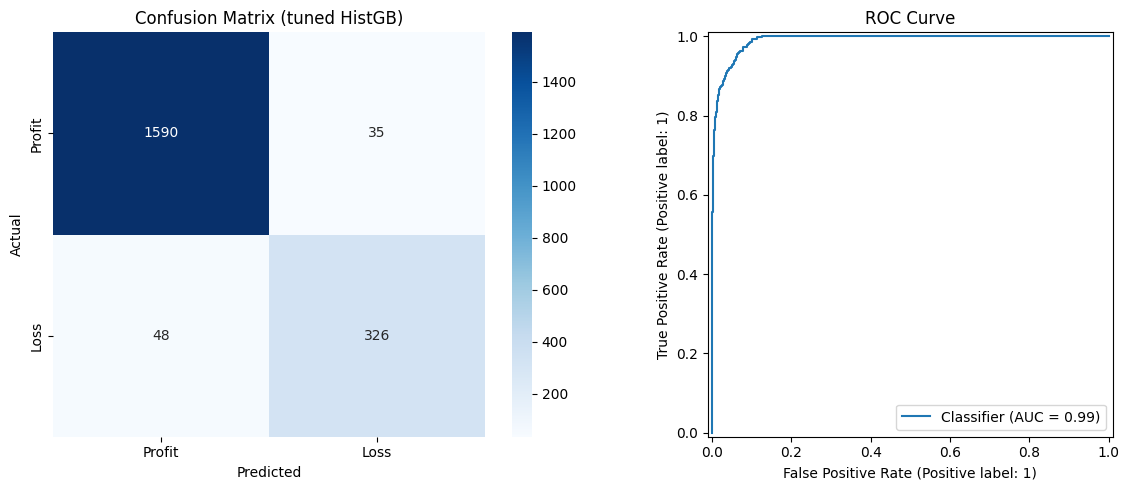

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_class_test, y_pred_best_clf),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=['Profit', 'Loss'],
    yticklabels=['Profit', 'Loss']
)
axes[0].set_title('Confusion Matrix (tuned HistGB)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

RocCurveDisplay.from_predictions(y_class_test, y_prob_best_clf, ax=axes[1])
axes[1].set_title('ROC Curve')

plt.tight_layout()
plt.show()

# Robustness Checks

A single random train/test split can be misleading when the target has extreme values (`Profit` ranges from about -6,600 to +8,400). Here I re-evaluate the Random Forest regressor in three harder ways. Preprocessing is inside a `Pipeline`, so it is fit only on each training fold.

1. **Repeated 5-fold CV (2 repeats):** how stable is R2 across different splits?
2. **Grouped CV by `Product ID`:** every validation product is *unseen* during training (a new product launch).
3. **Time split:** train on 2014-2016, test on 2017.

I report **Median AE** next to R2 because R2 is dominated by a handful of very large orders.

In [86]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, GroupKFold, cross_validate

X_all, y_all, groups = df[features], df[target], df['Product ID']

def rf_pipe(params):
    return Pipeline([('prep', clone(preprocessor)),
                     ('m', RandomForestRegressor(n_jobs=-1, random_state=42, **params))])

rf_configs = {'Base RF': {'n_estimators': 100}, 'Tuned RF': dict(rf_search.best_params_)}
scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'medae': 'neg_median_absolute_error'}

rob_rows, fold_r2 = [], {}
for name, params in rf_configs.items():
    # 1) repeated random CV
    r = cross_validate(rf_pipe(params), X_all, y_all, cv=RepeatedKFold(n_splits=5, n_repeats=2, random_state=42), scoring=scoring)
    fold_r2[(name, 'Random CV')] = r['test_r2']
    rob_rows.append({'Model': name, 'Scenario': 'Random CV (10 folds)', 'R2 mean': r['test_r2'].mean(),
                     'R2 min': r['test_r2'].min(), 'R2 max': r['test_r2'].max(),
                     'MAE': -r['test_mae'].mean(), 'Median AE': -r['test_medae'].mean()})
    # 2) grouped CV: unseen products
    r = cross_validate(rf_pipe(params), X_all, y_all, cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring)
    fold_r2[(name, 'New products')] = r['test_r2']
    rob_rows.append({'Model': name, 'Scenario': 'New products (GroupKFold)', 'R2 mean': r['test_r2'].mean(),
                     'R2 min': r['test_r2'].min(), 'R2 max': r['test_r2'].max(),
                     'MAE': -r['test_mae'].mean(), 'Median AE': -r['test_medae'].mean()})
    # 3) time split
    tr_m, te_m = (df['Year'] <= 2016).values, (df['Year'] == 2017).values
    p = rf_pipe(params).fit(X_all[tr_m], y_all[tr_m]); pr = p.predict(X_all[te_m])
    rob_rows.append({'Model': name, 'Scenario': 'Time split (test = 2017)', 'R2 mean': r2_score(y_all[te_m], pr),
                     'R2 min': np.nan, 'R2 max': np.nan,
                     'MAE': mean_absolute_error(y_all[te_m], pr),
                     'Median AE': np.median(np.abs(y_all[te_m] - pr))})

robustness = pd.DataFrame(rob_rows)
robustness.round(3)

,Model,Scenario,R2 mean,R2 min,R2 max,MAE,Median AE
0,Base RF,Random CV (10 folds),0.577,-0.246,0.909,20.929,1.747
1,Base RF,New products (GroupKFold),0.412,-0.684,0.857,23.740,1.935
2,Base RF,Time split (test = 2017),0.794,NaN,NaN,19.268,1.810
3,Tuned RF,Random CV (10 folds),0.657,0.165,0.883,23.844,3.962
4,Tuned RF,New products (GroupKFold),0.546,0.063,0.831,25.557,3.999
5,Tuned RF,Time split (test = 2017),0.787,NaN,NaN,22.785,4.071


/tmp/ipykernel_106/1421679728.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)


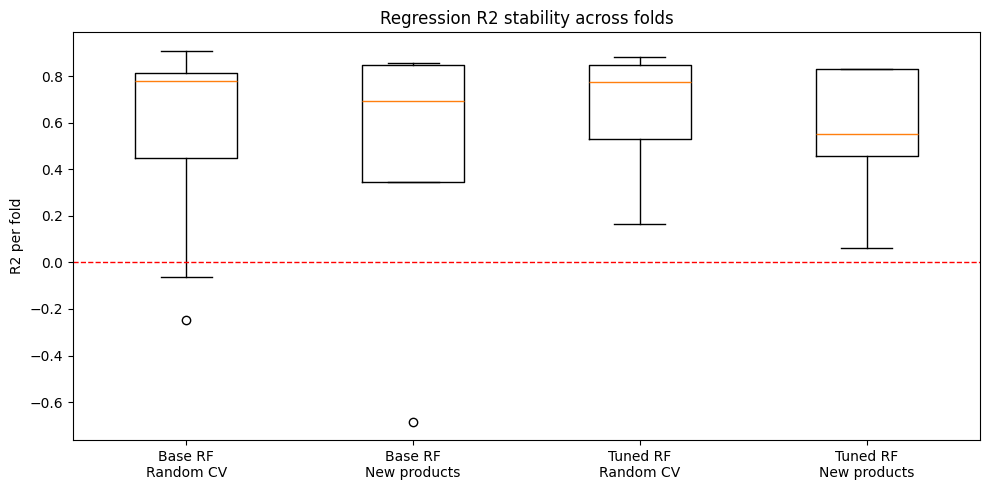

In [87]:
fig, ax = plt.subplots(figsize=(10, 5))
labels, data = [], []
for (name, scen), v in fold_r2.items():
    labels.append(f"{name}\n{scen}"); data.append(v)
ax.boxplot(data, labels=labels)
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_ylabel('R2 per fold'); ax.set_title('Regression R2 stability across folds')
plt.tight_layout(); plt.show()

## Classification Robustness and Threshold Choice

* **AUC under the same three scenarios** (using the tuned HistGradientBoosting classifier).
* **Decision threshold:** the default 0.5 gave Loss recall of about 0.81. The threshold is chosen from **out-of-fold predictions on the training set only**, then applied once to the test set.

In [88]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

clf_params = dict(clf_search.best_params_)
def clf_pipe():
    return Pipeline([('prep', clone(preprocessor)),
                     ('m', HistGradientBoostingClassifier(random_state=42, **clf_params))])

y_cls_all = df[target_class]
auc_rows = []
r = cross_validate(clf_pipe(), X_all, y_cls_all, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='roc_auc')
auc_rows.append({'Scenario': 'Random stratified CV', 'AUC mean': r['test_score'].mean(), 'AUC min': r['test_score'].min()})
r = cross_validate(clf_pipe(), X_all, y_cls_all, cv=GroupKFold(n_splits=5), groups=groups, scoring='roc_auc')
auc_rows.append({'Scenario': 'New products (GroupKFold)', 'AUC mean': r['test_score'].mean(), 'AUC min': r['test_score'].min()})
p = clf_pipe().fit(X_all[tr_m], y_cls_all[tr_m])
auc_rows.append({'Scenario': 'Time split (test = 2017)', 'AUC mean': roc_auc_score(y_cls_all[te_m], p.predict_proba(X_all[te_m])[:, 1]), 'AUC min': np.nan})
pd.DataFrame(auc_rows).round(3)

,Scenario,AUC mean,AUC min
0,Random stratified CV,0.991,0.989
1,New products (GroupKFold),0.985,0.981
2,Time split (test = 2017),0.991,NaN


In [89]:
from sklearn.metrics import precision_score, recall_score, fbeta_score

# Out-of-fold probabilities on the TRAIN set only
oof = cross_val_predict(best_clf, X_train_processed, y_class_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba')[:, 1]

thr_rows = []
for t in np.arange(0.15, 0.65, 0.05):
    pred = (oof >= t).astype(int)
    thr_rows.append({'threshold': round(t, 2),
                     'precision': precision_score(y_class_train, pred),
                     'recall': recall_score(y_class_train, pred),
                     'F1': fbeta_score(y_class_train, pred, beta=1),
                     'F2 (recall-weighted)': fbeta_score(y_class_train, pred, beta=2)})
thr_table = pd.DataFrame(thr_rows)
best_thr = float(thr_table.loc[thr_table['F2 (recall-weighted)'].idxmax(), 'threshold'])
print('Threshold chosen on out-of-fold train predictions (max F2):', best_thr)
thr_table.round(3)

Threshold chosen on out-of-fold train predictions (max F2): 0.15


,threshold,precision,recall,F1,F2 (recall-weighted)
0,0.15,0.735,0.970,0.836,0.912
1,0.20,0.770,0.951,0.851,0.908
2,0.25,0.803,0.927,0.861,0.899
3,0.30,0.832,0.912,0.870,0.895
4,0.35,0.858,0.893,0.875,0.886
5,0.40,0.878,0.877,0.878,0.877
6,0.45,0.899,0.860,0.879,0.868
7,0.50,0.915,0.840,0.876,0.854
8,0.55,0.927,0.819,0.870,0.838
9,0.60,0.940,0.798,0.863,0.823


In [90]:
# Apply once on the untouched test set: default 0.5 vs chosen threshold
final_rows = []
for label, t in [('Default 0.50', 0.5), (f'Chosen {best_thr:.2f}', best_thr)]:
    pred = (y_prob_best_clf >= t).astype(int)
    final_rows.append({'Threshold': label,
                       'Precision (Loss)': precision_score(y_class_test, pred),
                       'Recall (Loss)': recall_score(y_class_test, pred),
                       'F1 (Loss)': f1_score(y_class_test, pred),
                       'Accuracy': accuracy_score(y_class_test, pred)})
pd.DataFrame(final_rows).round(3)

,Threshold,Precision (Loss),Recall (Loss),F1 (Loss),Accuracy
0,Default 0.50,0.903,0.872,0.887,0.958
1,Chosen 0.15,0.722,0.973,0.829,0.925


# Modeling Conclusions

All numbers below come from running this notebook end to end on the Superstore dataset (9,994 rows).

## 1) Profit regression

* **Best single-split result:** the tuned Random Forest reaches **R2 = 0.875** (base model 0.850), MAE 21.0 and RMSE 81.6 on the test set. Linear Regression only reaches 0.535, so the profit relationship is clearly non-linear.
* **The single-split R2 overstates how stable the model is.** `Profit` has a few extreme orders (about -6,600 to +8,400), and they dominate R2:
  * Repeated 5-fold CV: base RF R2 averages **0.58** (folds range from -0.25 to 0.91); tuned RF averages **0.66** (0.17 to 0.88).
  * New products (grouped by `Product ID`): **0.41** base / **0.55** tuned.
  * Time split (train 2014-2016, test 2017): **0.79** for both models.
* **Typical orders are predicted very accurately.** Median absolute error is only about **$1.7-$4.0** in every scenario. The tuned RF is more stable across folds (better worst-case R2) but gives up about $2 of median accuracy compared with the base RF, a trade-off between robustness to large orders and precision on small ones.
* **Main drivers (permutation importance):** `Discount`, order size/price (`Sales`, `LogSales`, `UnitPrice`) and the Copiers sub-category. This matches the EDA finding that profit turns negative at discounts of 30% and above.
* **Practical reading:** the model is useful for estimating profit on orders for products already in the catalog. It is not reliable for individual very large orders or for brand-new products, and it should not be the only input for decisions on big-ticket orders.

## 2) Loss-making order classification

* The tuned HistGradientBoosting classifier reaches **ROC-AUC = 0.99** on the test set. Unlike the regressor, this holds in every robustness check: **0.991** (random CV), **0.985** (new products) and **0.991** (time split).
* At the default 0.5 threshold: Loss precision **0.90**, recall **0.87**, F1 **0.89**, accuracy **0.96**.
* **Threshold choice is a business decision.** Using out-of-fold training predictions (max F2), the chosen threshold of 0.15 raises Loss recall to **0.97** on the test set, at the cost of precision falling to **0.72**. Use a low threshold when missing a loss is expensive and a manual review of a false alarm is cheap; use about 0.5 for a balanced alert.

## 3) Limitations and next steps

* This is a sample dataset. `Sales`, `UnitPrice` and `LogSales` are known at order time, but because a product's unit price is nearly constant, they act partly as product identifiers; without them the regression R2 drops sharply on new data.
* `ShipDays` is excluded from the model because the ship date is not known when the order is placed.
* Possible improvements: quantile or Huber regression for large orders, per-category models, product cost data, and a business-defined cost for missed losses to set the classification threshold.